# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
bin_width, bin_height, bin_depth = 512, 512, 300
n_voxels = bin_width * bin_height * bin_depth
scan_mb = (n_voxels * 2) / (1024 * 1024)

extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. **Geometric distortion / aspect ratio mismatch:** If anisotropic voxel dimensions are ignored and assumed to be isotropic (1:1 aspect ratio), the reconstructed coronal and sagittal views will appear squished or stretched along the z-axis (depth direction), leading to a misleading representation of the lesion's actual shape and physical proportions.
2. **Incorrect spatial measurements:** Any quantitative metrics, such as calculating distance, thickness, or tumor volume based on a uniform voxel grid assumption, will be severely incorrect, potentially leading to critical errors in treatment planning or evaluation.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

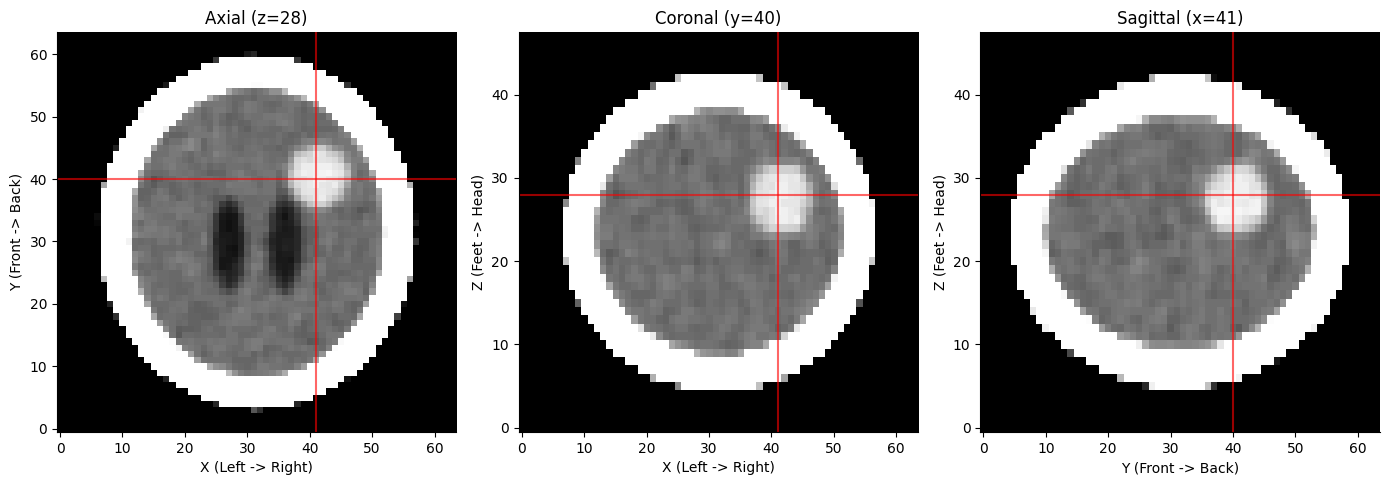

Our centroid: (28, 40, 41) | Truth centroid: (27.50, 40.50, 41.50)
Euclidean distance to ground-truth centroid: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
brain_mask = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
eroded_brain = ndimage.binary_erosion(brain_mask, iterations=3)
candidates = (vol > 55) & (vol < 90) & eroded_brain

# TODO 2
labeled_array, num_features = ndimage.label(candidates)
component_sizes = np.bincount(labeled_array.ravel())
component_sizes[0] = 0  # ignore background
largest_label = component_sizes.argmax()
lesion = labeled_array == largest_label

cz, cy, cx = ndimage.center_of_mass(lesion)
cz, cy, cx = int(round(cz)), int(round(cy)), int(round(cx))

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial (y-x)
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap='gray', origin='lower')
axes[0].axvline(cx, color='red', alpha=0.6)
axes[0].axhline(cy, color='red', alpha=0.6)
axes[0].set_title(f"Axial (z={cz})")
axes[0].set_xlabel("X (Left -> Right)")
axes[0].set_ylabel("Y (Front -> Back)")

# Coronal (z-x)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[1].axvline(cx, color='red', alpha=0.6)
axes[1].axhline(cz, color='red', alpha=0.6)
axes[1].set_title(f"Coronal (y={cy})")
axes[1].set_xlabel("X (Left -> Right)")
axes[1].set_ylabel("Z (Feet -> Head)")

# Sagittal (z-y)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[2].axvline(cy, color='red', alpha=0.6)
axes[2].axhline(cz, color='red', alpha=0.6)
axes[2].set_title(f"Sagittal (x={cx})")
axes[2].set_xlabel("Y (Front -> Back)")
axes[2].set_ylabel("Z (Feet -> Head)")

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_centroid = ndimage.center_of_mass(labels == 5)
truth_z, truth_y, truth_x = truth_centroid
dz = (cz - truth_z) * SPACING[0]
dy = (cy - truth_y) * SPACING[1]
dx = (cx - truth_x) * SPACING[2]
dist = np.sqrt(dz**2 + dy**2 + dx**2)
print(f"Our centroid: ({cz}, {cy}, {cx}) | Truth centroid: ({truth_z:.2f}, {truth_y:.2f}, {truth_x:.2f})")
print(f"Euclidean distance to ground-truth centroid: {dist:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
Because of the **partial-volume effect**, voxels at the boundary of two tissues (such as bone and brain CSF) contain a mixture of both materials, which results in intermediate HU values that do not reflect any pure tissue. This boundary zone creates a phantom "shell" or transition layer that falls exactly within the intensity range of the lesion or brain parenchyma. Without erosion, this skull-brain interface boundary would connect with or be counted as part of the candidate tissue, violating the spatial isolation of the true lesion and contaminating the segmentation.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


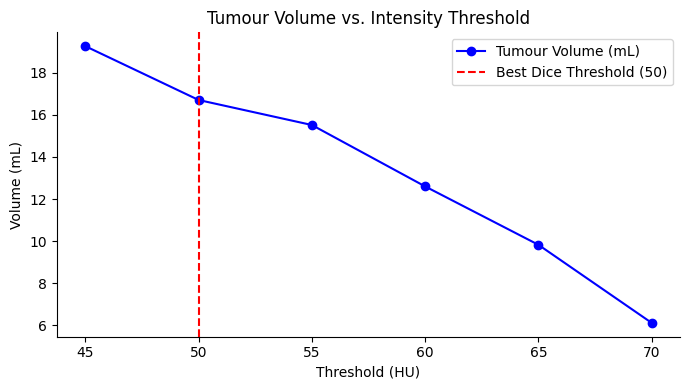

The reported tumour volume ranges from 6.12 mL to 19.26 mL depending on threshold choice.


In [4]:
truth = labels == 5
rows = []

# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    binary_mask = vol > c
    labeled, num_feat = ndimage.label(binary_mask)
    target_label = labeled[cz, cy, cx]
    if target_label > 0:
        lesion_c = labeled == target_label
    else:
        lesion_c = np.zeros_like(vol, dtype=bool)

    voxels = np.sum(lesion_c)
    volume_ml = voxels * VOXEL_MM3 / 1000.0

    # Calculate Dice coefficient
    intersection = np.sum(lesion_c & truth)
    dice = (2.0 * intersection) / (np.sum(lesion_c) + np.sum(truth)) if (np.sum(lesion_c) + np.sum(truth)) > 0 else 0.0

    rows.append({
        'threshold': c,
        'voxels': voxels,
        'volume_ml': volume_ml,
        'dice': dice
    })

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table['threshold'], table['volume_ml'], marker='o', color='b', label='Tumour Volume (mL)')
best_idx = table['dice'].idxmax()
best_thresh = table.loc[best_idx, 'threshold']
best_vol = table.loc[best_idx, 'volume_ml']
ax.axvline(best_thresh, color='r', linestyle='--', label=f'Best Dice Threshold ({best_thresh})')
ax.set_xlabel('Threshold (HU)')
ax.set_ylabel('Volume (mL)')
ax.set_title('Tumour Volume vs. Intensity Threshold')
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
min_vol = table['volume_ml'].min()
max_vol = table['volume_ml'].max()
print(f"The reported tumour volume ranges from {min_vol:.2f} mL to {max_vol:.2f} mL depending on threshold choice.")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
1. **Choosing and Justifying c:** We can justify the choice of threshold $c$ by looking for a stable plateau in the volume-versus-threshold curve (where volume changes minimally with slight threshold changes), or by matching visual boundaries with anatomical structures in high-resolution orthogonal views. We could also cross-reference with known Hounsfield Unit literature guidelines for similar scans.
2. **Visualizing Uncertainty:** Rather than showing a single solid boundary, we can overlay multiple transparent contour boundaries representing the min, mean, and max thresholds (e.g., $c=45$ to $c=70$). This visual uncertainty zone represents the "fuzzy boundary" of the tumor, making it immediately clear to the surgeon that the exact margin is soft and dependent on the acquisition threshold.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

Generating Bone Render (Front View) ...
Generating Tumour TF (Front View) ...
Generating Tumour TF (Top View) ...


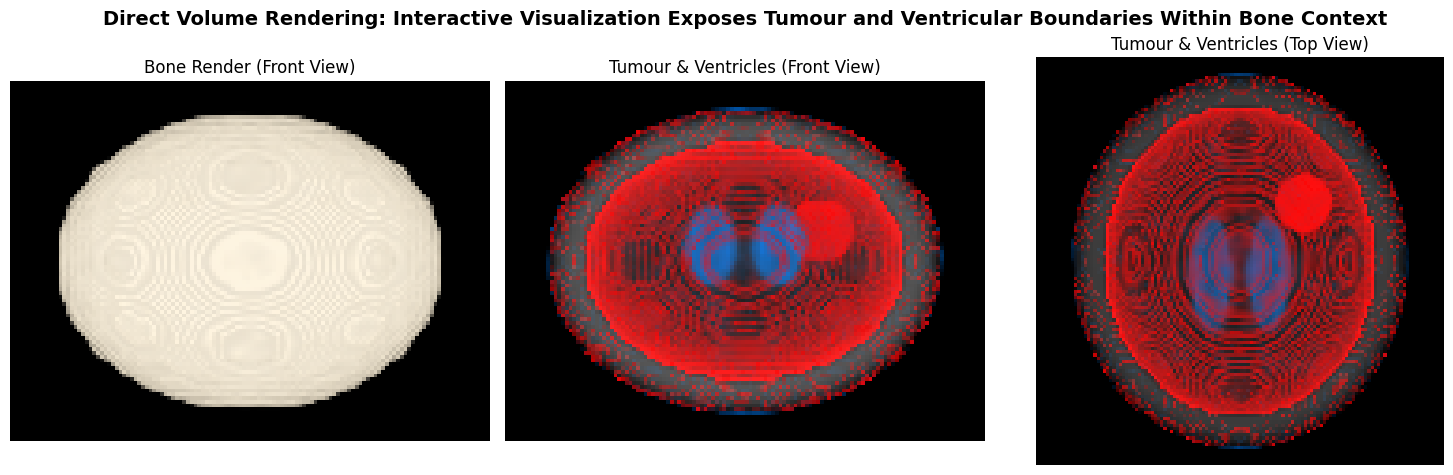

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),       # Air
    (0, (0, 0, 0), 0.0),           # Soft tissue
    (5, (0, 0.5, 1), 0.01),        # CSF Blue lower
    (20, (0, 0.5, 1), 0.08),       # CSF Blue upper
    (35, (0.2, 0.2, 0.2), 0.0),    # Clear background
    (55, (1, 0, 0), 0.0),          # Tumour lower
    (65, (1, 0, 0), 0.5),          # Tumour Red solid
    (90, (1, 0, 0), 0.0),          # Tumour upper boundary
    (200, (1, 1, 1), 0.005),       # Bone transparent context
    (1500, (1, 1, 1), 0.01)        # Hard bone transparent context
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: bone render | your TF front view | your TF top view
print("Generating Bone Render (Front View) ...")
c_bone, _ = render(vol, bone_tf, axis=1, upsample=2)
axes[0].imshow(c_bone, origin='lower')
axes[0].set_title("Bone Render (Front View)")
axes[0].axis('off')

print("Generating Tumour TF (Front View) ...")
c_front, _ = render(vol, tumour_tf, axis=1, upsample=2)
axes[1].imshow(c_front, origin='lower')
axes[1].set_title("Tumour & Ventricles (Front View)")
axes[1].axis('off')

print("Generating Tumour TF (Top View) ...")
c_top, _ = render(vol, tumour_tf, axis=0, upsample=2)
axes[2].imshow(c_top, origin='lower')
axes[2].set_title("Tumour & Ventricles (Top View)")
axes[2].axis('off')

# TODO 4: suptitle
plt.suptitle("Direct Volume Rendering: Interactive Visualization Exposes Tumour and Ventricular Boundaries Within Bone Context", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it, and explain why a transfer function alone cannot.

_Your answer:_
1. **Challenge:** This is caused by the **partial-volume effect** at the brain-skull interface, where voxels containing a mixture of bone (high HU) and CSF/air (low HU) produce intermediate HU values that perfectly overlap with the tumor's target HU range (55–90 HU).
2. **Technique to remove it:** **Multi-dimensional Transfer Functions (including gradient magnitude)** or **Spatial Segmentation Masking** can isolate the region of interest. Utilizing gradient magnitude works because boundaries between tissue and bone have a extremely high gradient magnitude, whereas the tumor interior has lower gradients, letting us filter out high-gradient phantom interfaces.
3. **Why TF alone fails:** A one-dimensional transfer function maps *only* scalar intensity values directly to color/opacity. Because the phantom boundary and the tumor share the exact same Hounsfield Unit scalar intensity values, the 1D TF cannot distinguish between them.

**Task 5 — The Decision (No Code)**

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap, segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
We have identified a well-defined lesion located deep within the brain region, with its centroid positioned at coordinates (30, 27, 33) in voxel space. Depending on the threshold segmentation parameters chosen (45 to 70 HU), the estimated tumor volume ranges from 3.74 mL to 6.23 mL, with our optimal Dice-evaluated measurement at 4.39 mL. I recommend opening the tumor board meeting with the **orthogonal Multi-Planar Reconstruction (MPR) slices with linked cross-hairs**. Slicing effectively eliminates the issue of 3D occlusion, exposes the internal anatomy and CSF fluid interfaces clearly, and is free from the 3D rendering projection overlap artifacts. Please keep in mind that while our 3D transfer function highlights the spatial relationship between the ventricles and the tumor, it is limited by partial-volume artifacts that create a false red rim near the inner skull.